![Banner](../images/09_01_banner_rs_banner.png)


# The Python Geospatial Environment

This module sets up the tools used for the rest of the course and introduces the building blocks every remote sensing workflow in Python relies on: NumPy arrays, labelled xarray objects, georeferencing with rioxarray, vector data with GeoPandas, lazy computation with Dask, and the CPU/GPU backend of GeoLattice's remote sensing toolkit, `geolattice.rsense`.


## Overview

This module sets up the tools used for the rest of the course and introduces the building blocks every remote sensing workflow in Python relies on: NumPy arrays, labelled xarray objects, georeferencing with rioxarray, vector data with GeoPandas, lazy computation with Dask, and the CPU/GPU backend of GeoLattice's remote sensing toolkit, `geolattice.rsense`.


## Core concepts

### Learning objectives

1. Create a reproducible environment (conda or pip) with the geospatial stack and GeoLattice.
2. Check versions and hardware with `rs.info()` and choose a CPU or GPU backend.
3. Treat satellite images as NumPy arrays and xarray DataArrays/Datasets with coordinates.
4. Attach and inspect coordinate reference systems (CRS) and affine transforms, and mosaic
   raster tiles.
5. Build and reproject vector data with GeoPandas and Shapely.
6. Process rasters lazily and in tiles with Dask and `rs.apply_tiled`.
7. Compare CPU and GPU performance.
8. Organise a remote sensing project for reproducibility.

### Data

Dataset are available for download in [GeoLattice Data Folder](https://www.dropbox.com/scl/fo/58n9t8sewax7pffrroxd3/AIWTrjKzklRedtYx0mczwcc?rlkey=0fat0am1b0aai5pieqyx0633j&dl=0)

| Source | Used for |
|---|---|
| Synthetic arrays in the notebook | NumPy, xarray, Dask and CPU/GPU examples |
| `/LC08_20150706_subset/DEM_TILES/` | Onondaga County DEM tiles for mosaicking and GeoPandas |
| `/LC09_L2SP_138043_20221216_20221223_02_T1/` | Landsat 9 NIR band for lazy/Dask reads |

### Contents

1. Installing the environment
2. Checking the installation and hardware
3. CPU and GPU backends in `geolattice.rsense`
4. NumPy: images are arrays
5. xarray: arrays with coordinates
6. rioxarray: georeferencing
7. GeoPandas and Shapely: vector data
8. Dask and tiled processing for large rasters
9. Benchmarking CPU (and GPU) performance
10. Organising a project
11. Summary and exercises


## Installing the environment


GeoLattice needs the compiled **GDAL** and **PROJ** libraries, with Python GDAL bindings that match
the installed GDAL. Install those first (conda-forge or your system package manager), then
install GeoLattice from its repository with the extras you need.

**Option A: conda / mamba (recommended).** Compiled geospatial libraries install most
reliably from conda-forge. Save this as `environment.yml` next to your GeoLattice clone:

```yaml
name: geolattice
channels: [conda-forge]
dependencies:
  - python=3.11
  - gdal
  - rasterio
  - rioxarray
  - geopandas
  - xarray
  - dask
  - jupyterlab
  - pip
  - pip:
      - -e "./GeoLattice[rsense,rsense-access,rsense-classify,rsense-viz,rsense-scale]"
```

then run `mamba env create -f environment.yml` and `mamba activate geolattice`.

**Option B: pip.** With GDAL already installed, from the root of the GeoLattice repository:

```bash
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\Scripts\activate
pip install -e ".[rsense,rsense-access,rsense-classify,rsense-viz,rsense-scale]" jupyterlab
```

or build and install a wheel (`python -m build`, then `pip install "dist/geolattice-0.3.9-*.whl[rsense]"`).

The remote sensing extras of GeoLattice are:

| Extra | Adds |
|---|---|
| `rsense` | Core: xarray, rioxarray, rasterio, scikit-image, geopandas |
| `rsense-access` | STAC, Planetary Computer, odc-stac, earthaccess |
| `rsense-sar`, `rsense-insar` | ASF search and sarsen; HyP3 SDK and h5py |
| `rsense-lidar`, `rsense-uav` | laspy and cloth-simulation filter; pyodm (OpenDroneMap) |
| `rsense-classify`, `rsense-xai` | scikit-learn and XGBoost; SHAP |
| `rsense-dl` | PyTorch, TorchGeo, segmentation-models-pytorch, Lightning |
| `rsense-gee`, `rsense-viz` | Earth Engine API and xee; matplotlib and leafmap |
| `rsense-scale`, `rsense-apps` | Dask distributed, Zarr, pystac; Streamlit templates |
| `rsense-gpu` | CuPy for CUDA 12 |
| `rsense-all` | Every group except `rsense-gpu` |

**GPU (optional, NVIDIA).** Add CuPy (and optionally cuCIM) matching your CUDA version:

```bash
pip install -e ".[rsense-gpu]"
pip install --extra-index-url=https://pypi.nvidia.com cuml-cu12   # GPU machine learning (optional)
```

**Google Colab.** Upload or clone the GeoLattice repository into the session, then run
`!pip install -e "./GeoLattice[rsense,rsense-viz]"` in the first cell. Choose
*Runtime → Change runtime type → GPU* and add the `rsense-gpu` extra to use the GPU.

If `import geolattice` fails with `libgdal.so... cannot open shared object file` or
`No module named '_gdal'`, the GDAL bindings do not match the GDAL library; the
*Troubleshooting* section of the GeoLattice README explains the fix.


## Checking the installation and hardware


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Setup for the Python geospatial environment notebook.
#
# 1. Show plots inside the notebook, and hide noisy UserWarnings from matplotlib
#    and the geospatial libraries.
# 2. Import the core stack: NumPy (arrays), pandas (tables), xarray (labelled
#    arrays), GeoPandas (vector data) and matplotlib (plots).
# 3. Import geolattice and the remote-sensing package geolattice.rsense as rs.
# 4. Set a sharp figure style, then print the package versions so the run is
#    reproducible.

%matplotlib inline
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings

import time                 # used later to time CPU vs GPU work
from pathlib import Path    # file and folder paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
import geolattice.rsense as rs  # GeoLattice remote sensing subpackage

# figure resolution and a light grid
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("geolattice", geolattice.__version__, "| geolattice.rsense", rs.__version__)  # versions

geolattice 0.3.9 | geolattice.rsense 0.2.0.dev0


`rs.info()` reports library versions and every compute device `geolattice.rsense` can see.
Include it in bug reports. (The key `pyrsense_backend` keeps the name used by PyRSense,
from which `geolattice.rsense` was ported.)


In [ ]:
# Inspect the current geolattice.rsense environment.
#
# rs.info() returns a dictionary of versions and hardware (Python, NumPy, xarray,
# rasterio, Dask, CuPy, and so on). The GPU list is printed in the next cell, so
# it is left out of this table. Everything else becomes one column named "value".

info = rs.info()
# GeoLattice version plus every environment field except the GPU list
table = pd.Series({"geolattice": geolattice.__version__, **{k: v for k, v in info.items() if k != "gpus"}}, name="value")
table.to_frame()  # show as a table

,value
geolattice,0.3.9
pyrsense_backend,cpu
available_backends,"[cpu, cuda]"
python,3.11.16
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
xarray,2026.7.0
dask,2026.7.1
rasterio,1.4.4
rioxarray,0.19.0


In [ ]:
# List compute backends and any detected GPUs.
#
# 1. rs.available_backends() reports which array libraries can run here (cpu,
#    and cuda when an NVIDIA GPU and CuPy are present).
# 2. Each GPU entry has an id, a name, and free/total memory in gigabytes.
# 3. If the list is empty, say so plainly.

print("Available backends:", rs.available_backends())
for gpu in info["gpus"] or []:  # each detected GPU (none -> empty list)
    # its name and memory
    print(f"GPU {gpu['id']}: {gpu['name']}, {gpu['memory_total_gb']:.1f} GB total, {gpu['memory_free_gb']:.1f} GB free")
if not info["gpus"]:  # no GPU found
    print("GPUs: none detected")  # say so

Available backends: ['cpu', 'cuda']
GPU 0: NVIDIA RTX A5500 Laptop GPU, 16.8 GB total, 14.8 GB free


## CPU and GPU backends in `geolattice.rsense`


`geolattice.rsense` runs the same code on the CPU (NumPy) or an NVIDIA GPU (CuPy). You choose the
backend once; every native algorithm then computes on it:

- `rs.set_backend("auto")` picks CUDA if available, then Apple MPS (deep learning only), then CPU.
- `rs.set_backend("cuda:1")` selects a specific GPU.
- `with rs.device("cuda"): ...` switches temporarily.
- On a machine **without CUDA**, requesting `"cuda"` **falls back to the CPU with a warning**
  instead of crashing, so notebooks run anywhere. Asking for a GPU index that does not exist
  on a CUDA machine is a configuration error and raises `ValueError`.


In [ ]:
# Choose the array backend, then temporarily override it.
#
# geolattice.rsense runs the same functions on NumPy (CPU) or CuPy (NVIDIA GPU).
# rs.set_backend("auto") picks CUDA when a GPU is available, otherwise CPU.
#
# 1. Turn auto mode on and print whether array math will use the GPU.
# 2. rs.device("cpu") is a context manager: code inside the block runs on the
#    CPU, then the previous backend is restored. The print after the block
#    should match the print before it.
# 3. Asking for a device that does not exist (cuda:7) raises ValueError, or a
#    fallback warning on a CPU-only machine. Catch that so the notebook continues.

backend = rs.set_backend("auto")
# the backend and whether array maths runs on the GPU
print("Active backend:", backend, "| array math on GPU:", backend.array_gpu)

with rs.device("cpu") as b:  # temporarily switch to the CPU backend
    print("Inside a CPU block:", b)  # the backend inside the block
print("After the block:", rs.get_backend())  # back to the previous backend

with warnings.catch_warnings(record=True) as caught:  # record warnings instead of printing them
    warnings.simplefilter("always")  # record every warning, even repeated ones
    try:
        with rs.device("cuda:7"):  # ask for a GPU that does not exist
            pass
    except ValueError as err:
        print("Requesting cuda:7 →", err)  # the error message
    for w in caught:                                   # on a CPU-only machine: the fallback warning
        print("Warning:", str(w.message)[:90], "...")  # the first 90 characters of each warning

Active backend: cuda:0 | array math on GPU: True
Inside a CPU block: cpu
After the block: cuda:0
Requesting cuda:7 → cuda:7 requested but only 1 CUDA device(s) found


`rs.to_device()` and `rs.to_cpu()` move NumPy arrays, DataArrays and Datasets between host and
GPU memory; coordinates stay on the host. Native functions return results **in the same
memory space as their input**, so you can keep CPU data and still get GPU speed by changing
only the backend.


In [ ]:
# Move an array between host (CPU) memory and device (GPU) memory.
#
# 1. Build a small random float32 cube: 4 bands × 512 × 512 pixels.
# 2. rs.to_device sends it to the active backend. On a GPU machine that is CuPy;
#    on CPU it stays NumPy. rs.to_cpu always brings it back to NumPy.
# 3. memory_report() summarises device memory use.
# 4. recommend_chunks suggests Dask chunk sizes for a much larger cube
#    (10 dates × 20,000 × 20,000), aiming for about 128 MB per chunk.

arr = np.random.default_rng(0).random((4, 512, 512), dtype=np.float32)
on_dev = rs.to_device(arr)  # move the array to the active device (a no-op on the CPU)
# module of the array before and after copying back to the CPU
print(type(on_dev).__module__, "→", type(rs.to_cpu(on_dev)).__module__)
print("Memory:", rs.backend.memory_report())  # memory available on the device
# chunk sizes Dask should use for a large cube
print("Suggested Dask chunks for a 10-date 20,000 × 20,000 cube:",
      rs.backend.recommend_chunks((10, 20_000, 20_000), "float32", target_mb=128))

cupy → numpy
Memory: {'backend': 'cuda:0', 'host_total_gb': 132.3, 'host_free_gb': 104.57, 'gpu_free_gb': 14.82, 'cupy_pool_used_gb': 0.004}
Suggested Dask chunks for a 10-date 20,000 × 20,000 cube: (10, 1536, 1536)


On this machine `"auto"` selected the NVIDIA GPU (`cuda:0`), so the rest of the notebook runs
on it wherever `geolattice.rsense` computes. `rs.to_device` turned the NumPy array into a CuPy array
and `rs.to_cpu` brought it back. On a CPU-only machine the same cells run unchanged and report
`cpu`.

Array computations use `float32` by default, which halves memory compared with `float64` and is
ample for reflectance and backscatter. `rs.backend.set_precision("float64")` switches it if needed.


## NumPy: images are arrays


A single-band image is a 2-D array (rows × columns); a multispectral image is 3-D
(bands × rows × columns). Most remote sensing operations are array operations:
arithmetic between bands, boolean masks and statistics. Here we build a tiny synthetic
4-band "scene" with a lake and a field to practise.


In [ ]:
# Build a tiny synthetic 4-band reflectance image (blue, green, red, NIR).
#
# A real satellite image is just a numeric array. This one is 100 rows by 120
# columns so the later steps are easy to see.
#
# 1. mgrid makes row and column index grids.
# 2. A circle becomes a lake and a rectangle becomes a crop field. Every other
#    pixel is bare soil. Each surface gets its own reflectance in the four bands,
#    plus a little Gaussian noise.
# 3. The top-left 5×5 pixels are set to NaN, which is how rasters mark missing data.
# 4. Print the shape and the NIR mean, ignoring those NaNs.

rng = np.random.default_rng(42)
rows, cols = 100, 120  # image size
yy, xx = np.mgrid[0:rows, 0:cols]  # row and column index of every pixel
lake = (yy - 40) ** 2 + (xx - 35) ** 2 < 15 ** 2          # circle: a lake
field = (yy > 55) & (xx > 60)                             # rectangle: a crop field

# reflectance per band for background soil, lake and field (blue, green, red, nir)
soil, water, crop = [0.08, 0.12, 0.16, 0.25], [0.06, 0.05, 0.03, 0.01], [0.04, 0.08, 0.05, 0.45]
img = np.empty((4, rows, cols), dtype=np.float32)  # empty 4-band image
for b in range(4):  # each band
    # water, crop or bare soil value plus a little noise
    img[b] = np.where(lake, water[b], np.where(field, crop[b], soil[b])) + rng.normal(0, 0.01, (rows, cols))
img[:, :5, :5] = np.nan                                # a patch of missing data

print("shape (bands, rows, cols):", img.shape, "| dtype:", img.dtype)  # shape and data type
print("NIR mean, ignoring NaN:", round(float(np.nanmean(img[3])), 3))  # mean NIR, ignoring missing values

shape (bands, rows, cols): (4, 100, 120) | dtype: float32
NIR mean, ignoring NaN: 0.279


Water pixels: 636 (true lake area: 697)


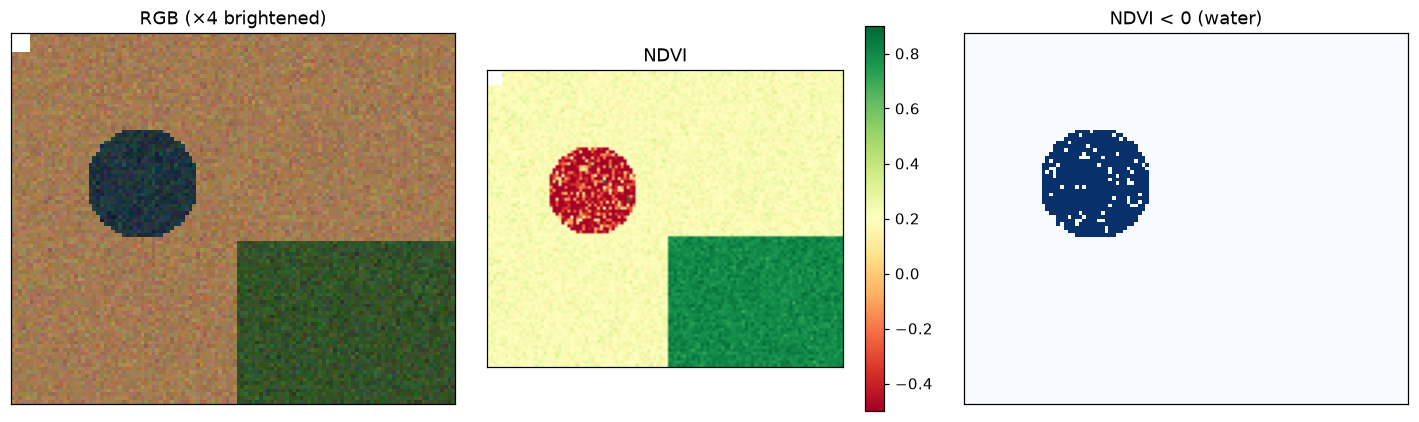

In [ ]:
# Band math and a simple water mask on the synthetic image.
#
# NDVI = (NIR − red) / (NIR + red). Vegetation is high (the crop), water is
# negative (the lake), soil sits in between.
#
# 1. Pull red (band index 2) and NIR (band index 3) and compute NDVI element-wise.
# 2. Treat NDVI < 0 as water and compare that count with the true lake area.
# 3. Draw three panels: a brightened RGB, the NDVI map, and the boolean water mask.

red, nir = img[2], img[3]
ndvi = (nir - red) / (nir + red)                       # element-wise band math
water_mask = ndvi < 0                                  # boolean mask
# detected water pixels vs the true lake size
print(f"Water pixels: {water_mask.sum()} (true lake area: {lake.sum()})")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))  # three panels
# imshow expects (row, col, band), so move the band axis from the front to the end.
# Multiplying by 4 just brightens dark reflectance for display.
axes[0].imshow(np.clip(img[[2, 1, 0]].transpose(1, 2, 0) * 4, 0, 1)); axes[0].set_title("RGB (×4 brightened)")
# NDVI with a colour bar
im = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-0.5, vmax=0.9); axes[1].set_title("NDVI"); plt.colorbar(im, ax=axes[1])
axes[2].imshow(water_mask, cmap="Blues"); axes[2].set_title("NDVI < 0 (water)")  # the water mask
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

Two habits avoid most beginner bugs: **convert integers to float before division** (integer
DNs overflow or truncate), and **use NaN-aware functions** (`np.nanmean`, `np.nanpercentile`)
when images contain missing data.


In [ ]:
# Show why remote-sensing math should use float, not integer digital numbers.
#
# Landsat DNs are often stored as uint16 (0 to 65,535). Adding two large uint16
# values wraps around instead of overflowing to a bigger number. Casting to
# float32 first gives the true sum. The same trap appears in radiance and
# reflectance scaling, so convert to float before any band math.

dn = np.array([60000, 50000], dtype=np.uint16)
# uint16 wraps around on overflow; float does not
print("uint16 sum overflows:", dn + dn, "| as float:", dn.astype(np.float32) + dn)

uint16 sum overflows: [54464 34464] | as float: [120000. 100000.]


## Xarray: arrays with coordinates


Raw arrays lose track of *where* and *when* each pixel is. **xarray** attaches named
dimensions and coordinate labels, so you select by map coordinates or dates instead of
indices. A `DataArray` is one labelled array; a `Dataset` is a collection of DataArrays
sharing coordinates, a natural fit for one variable per band. `geolattice.rsense` is built on xarray.


In [ ]:
# Wrap the NumPy image as an xarray DataArray with real map coordinates.
#
# A plain array only knows "row 10, column 20". xarray also stores what those
# axes mean: band name, easting and northing.
#
# 1. Build 10 m pixel centres. Easting increases to the right. Northing
#    decreases as you go down the image, which is how map coordinates work.
# 2. Attach band names (blue, green, red, nir) and a units/sensor label.
# 3. Displaying scene prints the dimensions, coordinates and attributes.

x = 400_000 + 10 * (np.arange(cols) + 0.5)          # 10 m pixels, UTM easting
y = 4_700_000 - 10 * (np.arange(rows) + 0.5)        # northing decreases down the image
scene = xr.DataArray(img, dims=("band", "y", "x"),  # the array as a labelled DataArray: band, y and x
                     coords={"band": ["blue", "green", "red", "nir"], "y": y, "x": x},
                     name="reflectance", attrs={"units": "reflectance", "sensor": "synthetic"})
scene  # show it

<xarray.DataArray 'reflectance' (band: 4, y: 100, x: 120)> Size: 192kB
array([[[       nan,        nan,        nan, ..., 0.08021852,
         0.09601779, 0.07760645],
        [       nan,        nan,        nan, ..., 0.07837334,
         0.06937586, 0.07470561],
        [       nan,        nan,        nan, ..., 0.08270343,
         0.07136655, 0.07852472],
        ...,
        [0.08424351, 0.09936102, 0.07175189, ..., 0.0280356 ,
         0.03821672, 0.05097295],
        [0.08970178, 0.07202707, 0.07454441, ..., 0.02578622,
         0.0367844 , 0.04041231],
        [0.07801793, 0.06357865, 0.09151591, ..., 0.04837477,
         0.03066577, 0.02602613]],

       [[       nan,        nan,        nan, ..., 0.11655483,
         0.12722602, 0.12288   ],
        [       nan,        nan,        nan, ..., 0.12145507,
         0.1209279 , 0.12536262],
        [       nan,        nan,        nan, ..., 0.123868  ,
         0.12499482, 0.116561  ],
...
        [0.17916375, 0.14138225, 0.16215959, ..., 0.0535407 ,
         0.04813141, 0.05386442],
        [0.15270077, 0.17980085, 0.13608773, ..., 0.04845568,
         0.04215565, 0.05373814],
        [0.17394361, 0.17732339, 0.17703983, ..., 0.05316027,
         0.04442975, 0.03778417]],

       [[       nan,        nan,        nan, ..., 0.2650684 ,
         0.24037589, 0.24388441],
        [       nan,        nan,        nan, ..., 0.26330468,
         0.24168578, 0.25230408],
        [       nan,        nan,        nan, ..., 0.26048833,
         0.25621527, 0.2539293 ],
        ...,
        [0.24686368, 0.2376909 , 0.26013803, ..., 0.44813022,
         0.43454045, 0.45030516],
        [0.23673807, 0.23624875, 0.23902422, ..., 0.44488522,
         0.45368332, 0.44104296],
        [0.24936336, 0.27462253, 0.24796903, ..., 0.46440455,
         0.4409013 , 0.45444104]]], shape=(4, 100, 120), dtype=float32)
Coordinates:
  * band     (band) <U5 80B 'blue' 'green' 'red' 'nir'
  * y        (y) float64 800B 4.7e+06 4.7e+06 4.7e+06 ... 4.699e+06 4.699e+06
  * x        (x) float64 960B 4e+05 4e+05 4e+05 ... 4.012e+05 4.012e+05
Attributes:
    units:    reflectance
    sensor:   synthetic

In [ ]:
# Index the DataArray two ways, then turn bands into variables.
#
# .sel uses coordinate values (band name, easting, northing). method="nearest"
# is needed because 400355 may not land on an exact pixel centre.
# .isel uses integer positions: band 3 is NIR, row 50, column 50.
# .to_dataset(dim="band") makes one data variable per band, which is the shape
# geolattice.rsense index functions expect.

print(scene.sel(band="nir").sel(x=400_355, y=4_699_605, method="nearest").item())   # by coordinates
print(scene.isel(band=3, y=50, x=50).item())                                         # by position
ds = scene.to_dataset(dim="band")                                                    # one variable per band
print(list(ds.data_vars))  # variable names of the Dataset

-0.008103086613118649
0.2575767934322357
['blue', 'green', 'red', 'nir']


Because `geolattice.rsense` knows the canonical band names, any of its 119 spectral indices works
on this Dataset directly:


In [ ]:
# Compute spectral indices with rs.optical.index on the band Dataset.
#
# The function looks up each index formula from the canonical band names
# (red, nir, and so on). Here we ask for NDVI, NDWI and SAVI, then take the
# spatial mean of each and round to 3 decimals.

rs.optical.index(ds, ["NDVI", "NDWI", "SAVI"]).mean().to_pandas().round(3)


NDVI    0.295
NDWI   -0.364
SAVI    0.234
dtype: float64

xarray shines with **time series**. We simulate a season of NDVI for this scene, with a
growing crop field, and use label-based time selection, resampling and grouping.


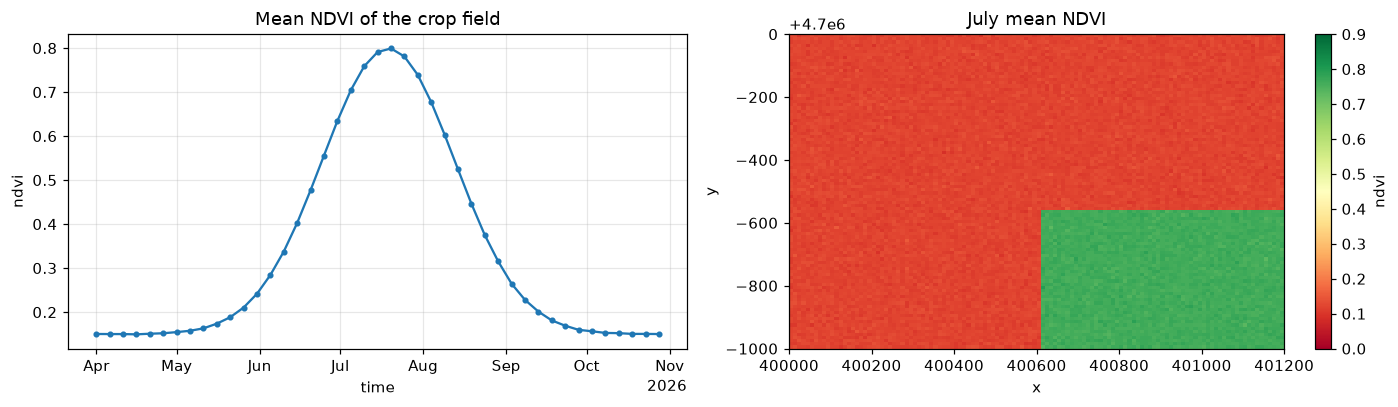

In [ ]:
# Build a small NDVI time cube and summarise it.
#
# 1. Dates every 5 days from April through October. A Gaussian bump centred on
#    day-of-year 200 stands in for crop green-up and senescence. Field pixels
#    follow that curve; everywhere else stays near 0.12 (soil), plus noise.
# 2. resample(time="1MS") collapses the 5-day series to monthly means.
# 3. Average the cube over the field and plot that series next to the July map.

dates = pd.date_range("2026-04-01", "2026-10-31", freq="5D")
doy = dates.dayofyear.values  # day of year of each date
season = 0.15 + 0.65 * np.exp(-((doy - 200) / 35.0) ** 2)                 # crop green-up and harvest
# crop NDVI follows the seasonal curve, the rest stays near 0.12, plus noise
ndvi_t = np.where(field, season[:, None, None], 0.12) + rng.normal(0, 0.02, (len(dates), rows, cols))
# the time series as a DataArray (time, y, x)
cube = xr.DataArray(ndvi_t.astype("float32"), dims=("time", "y", "x"),
                    coords={"time": dates, "y": y, "x": x}, name="ndvi")

monthly = cube.resample(time="1MS").mean()  # monthly means
# mean NDVI of the crop field on each date
field_series = cube.where(xr.DataArray(field, dims=("y", "x"), coords={"y": y, "x": x})).mean(("y", "x"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))  # two panels
# the field's time series
field_series.plot(ax=axes[0], marker="o", ms=3); axes[0].set_title("Mean NDVI of the crop field")
monthly.sel(time="2026-07").squeeze().plot(ax=axes[1], cmap="RdYlGn", vmin=0, vmax=0.9)  # the July mean map
axes[1].set_title("July mean NDVI")  # title
plt.tight_layout(); plt.show()  # arrange and draw

## Rioxarray: georeferencing


Coordinates alone don't say *which* coordinate system they are in. **rioxarray** adds the
`.rio` accessor (loaded automatically by `geolattice.rsense`), which stores the CRS and exposes the
affine transform, bounds and resolution, and powers reprojection, clipping and writing.


In [ ]:
# Attach a coordinate reference system with rioxarray.
#
# Coordinates alone do not say which system they are in. rio.write_crs tags the
# array as EPSG:32618 (WGS 84 / UTM zone 18N). It does not warp the pixels.
#
# Then print four things rioxarray can now answer: the CRS, the pixel size,
# the geographic bounds, and the affine transform that maps pixel index to
# map coordinates.

scene = scene.rio.write_crs("EPSG:32618")             # WGS 84 / UTM zone 18N
print("CRS:        ", scene.rio.crs)  # coordinate reference system
print("Resolution: ", scene.rio.resolution())  # pixel size
print("Bounds:     ", scene.rio.bounds())  # extent
print("Transform:\n", scene.rio.transform())  # affine transform (pixel -> map)

CRS:         EPSG:32618
Resolution:  (10.0, -10.0)
Bounds:      (400000.0, 4699000.0, 401200.0, 4700000.0)
Transform:
 | 10.00, 0.00, 400000.00|
| 0.00,-10.00, 4700000.00|
| 0.00, 0.00, 1.00|


The **affine transform** maps pixel (column, row) to map (x, y):
$x = a\,col + b\,row + c$, $y = d\,col + e\,row + f$. Here $a = 10$ m, $e = -10$ m (rows go
south) and $(c, f)$ is the upper-left corner.

Now the same operations on real files from the GeoLattice data folder
`Data/00_shared/data_remote_sensing/`:

| File | Contents |
|---|---|
| `LC08_20150706_subset/DEM_TILES/Onondaga_DEM0-3.TIF` | Four elevation tiles covering Onondaga County, New York (geographic WGS 84, about 0.0011° ≈ 120 m) |
| `LC09_L2SP_138043_20221216_20221223_02_T1/..._SR_B5.TIF` | A full Landsat 9 Level-2 NIR band, 5,565 × 5,571 pixels (northwestern Bangladesh, UTM 45N) |


In [ ]:
# Point at the local tutorial files under data/data_remote_sensing.
#
# 1. Four Onondaga County DEM tiles, used for the mosaic in the next cell.
# 2. One Landsat 9 Level-2 NIR band (SR_B5), used later for the lazy-read demo.
# 3. Print the file names and how large the Landsat band is on disk.

DATA = Path("../../../../Data/00_shared/data_remote_sensing")
# the DEM tiles of Onondaga County
DEM_TILES = sorted((DATA / "LC08_20150706_subset" / "DEM_TILES").glob("Onondaga_DEM*.TIF"))
L9_B5 = (DATA / "LC09_L2SP_138043_20221216_20221223_02_T1"  # a large Landsat 9 band
         / "LC09_L2SP_138043_20221216_20221223_02_T1_SR_B5.TIF")
# file names and size
print([p.name for p in DEM_TILES], "|", L9_B5.name, f"{L9_B5.stat().st_size / 1e6:.0f} MB")

['Onondaga_DEM0.TIF', 'Onondaga_DEM1.TIF', 'Onondaga_DEM2.TIF', 'Onondaga_DEM3.TIF'] | LC09_L2SP_138043_20221216_20221223_02_T1_SR_B5.TIF 63 MB


In [ ]:
# Read the DEM tiles and mosaic them onto one grid.
#
# 1. rs.read opens each GeoTIFF. squeeze drops a length-1 band dimension so the
#    result is a 2-D elevation map.
# 2. Print each tile's shape and bounds, which should meet at shared edges.
# 3. rs.mosaic merges them. Then report the mosaic CRS, shape, resolution in
#    degrees, the elevation range, and a UTM zone that would suit this area.

tiles = [rs.read(p).squeeze("band", drop=True) for p in DEM_TILES]
for p, t in zip(DEM_TILES, tiles):  # each tile
    print(f"{p.name}: shape {t.shape}, bounds {[round(v, 3) for v in t.rio.bounds()]}")  # its shape and bounds

dem = rs.mosaic(tiles)                                     # merge the four tiles onto one grid
print("\nMosaic CRS:", dem.rio.crs, "| shape:", dem.shape,  # CRS and shape of the mosaic
      "| resolution (deg):", [round(r, 6) for r in dem.rio.resolution()])
print(f"Elevation range: {float(dem.min()):.0f}-{float(dem.max()):.0f} m")  # elevation range
print("Suggested projected CRS: EPSG", rs.core.estimate_utm_crs(dem))  # a suitable UTM zone for this area

Onondaga_DEM0.TIF: shape (222, 267), bounds [-76.5, 42.771, -76.198, 43.023]
Onondaga_DEM1.TIF: shape (222, 267), bounds [-76.198, 42.771, -75.895, 43.023]
Onondaga_DEM2.TIF: shape (221, 267), bounds [-76.5, 43.023, -76.198, 43.273]
Onondaga_DEM3.TIF: shape (221, 267), bounds [-76.198, 43.023, -75.895, 43.273]

Mosaic CRS: EPSG:4326 | shape: (443, 534) | resolution (deg): [0.001133, -0.001133]
Elevation range: 108-623 m
Suggested projected CRS: EPSG 32618


## GeoPandas and Shapely: vector data


Field plots, administrative boundaries and training samples are vector data. **GeoPandas**
is pandas with a geometry column; **Shapely** provides the geometry operations. We create
three sites inside the Onondaga DEM, reproject them to UTM so distances are in metres, and
buffer them.


In [ ]:
# Vector workflow: study sites as points, then project, buffer and sample elevation.
#
# 1. Three sites are stored as longitude/latitude points (EPSG:4326).
# 2. estimate_utm_crs picks a local UTM zone. Buffering by 5,000 only means
#    5 km after that reprojection, because degrees are not metres.
# 3. Distance between Syracuse and Green Lakes is then a straight line in metres.
# 4. Sample the DEM at each original lon/lat point (nearest pixel) and drop the
#    buffer column so the table stays compact.

sites = gpd.GeoDataFrame(
    {"site": ["Syracuse", "Onondaga Lake", "Green Lakes State Park"],
     "landcover": ["urban", "lake", "forest and meromictic lakes"]},
    geometry=gpd.points_from_xy([-76.147, -76.205, -75.970], [43.048, 43.090, 43.058]), crs=4326)
utm = rs.core.estimate_utm_crs(sites)  # UTM zone for the sites
sites_utm = sites.to_crs(utm)  # reproject to metres
sites_utm["buffer_5km"] = sites_utm.buffer(5_000)          # 5 km, because the CRS is in metres
print("Projected CRS:", sites_utm.crs)  # the projected CRS
print("Distance Syracuse → Green Lakes State Park: "  # a distance in kilometres
      f"{sites_utm.geometry.iloc[0].distance(sites_utm.geometry.iloc[2]) / 1000:.1f} km")
# Sample elevation in geographic coordinates: the DEM itself is still lon/lat.
sites_utm["elevation_m"] = [float(dem.sel(x=pt.x, y=pt.y, method="nearest")) for pt in sites.geometry]
sites_utm.drop(columns="buffer_5km")  # show the table without the buffer column

Projected CRS: EPSG:32618
Distance Syracuse → Green Lakes State Park: 14.5 km


,site,landcover,geometry,elevation_m
0,Syracuse,urban,POINT (406582.292 4766783.464),121.208603
1,Onondaga Lake,lake,POINT (401925.415 4771513.814),110.427002
2,Green Lakes State Park,forest and meromictic lakes,POINT (421011.043 4767712.152),145.333710


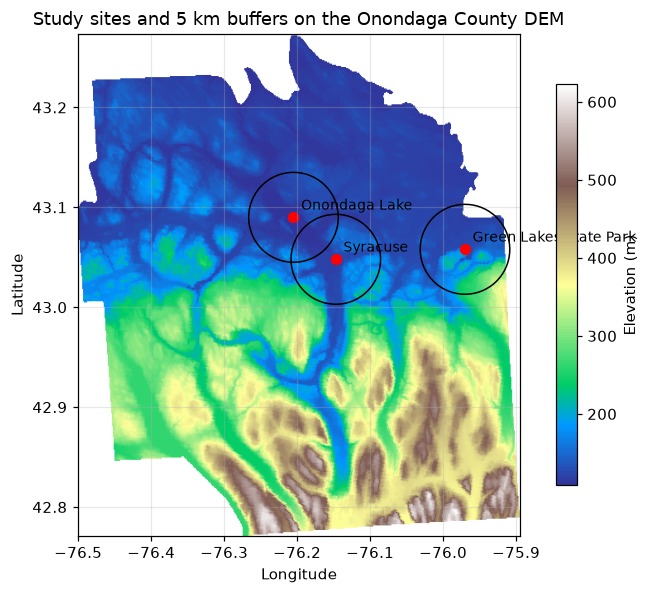

In [ ]:
# Map the DEM with the study sites and their 5 km buffers.
#
# imshow needs an extent (left, right, bottom, top) so the axes are longitude
# and latitude rather than pixel index. The buffers were built in UTM, so they
# are projected back to EPSG:4326 before drawing. Site names are offset a few
# points up and to the right of each marker.

fig, ax = plt.subplots(figsize=(7, 5.5))
xmin, ymin, xmax, ymax = dem.rio.bounds()  # extent of the DEM
im = ax.imshow(dem.values, cmap="terrain", extent=[xmin, xmax, ymin, ymax])  # the DEM in map coordinates
plt.colorbar(im, ax=ax, label="Elevation (m)", shrink=0.8)  # colour bar
# the 5 km buffers, drawn in lon/lat
gpd.GeoSeries(sites_utm["buffer_5km"], crs=utm).to_crs(4326).boundary.plot(ax=ax, color="k", lw=1)
sites.plot(ax=ax, color="red", markersize=40)  # the sites
for _, r in sites.iterrows():  # each site
    # its name
    ax.annotate(r.site, (r.geometry.x, r.geometry.y), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_title("Study sites and 5 km buffers on the Onondaga County DEM")  # title
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")  # axis labels
plt.tight_layout(); plt.show()  # arrange and draw

The four tiles share one grid, so `rs.mosaic` joins them into a 443 × 534 DEM covering
108-623 m, from the Onondaga Lake shore up to the hills of the southern county. The site
elevations sampled from it are plausible: Onondaga Lake 110 m, Syracuse 121 m and Green
Lakes 145 m. `rs.core.estimate_utm_crs` chose UTM zone 18N (EPSG:32618) for the area, so
distances (14.5 km from Syracuse to Green Lakes) and the 5 km buffers are in metres. Buffering
in degrees would give ellipses whose size depends on latitude.


## Dask and tiled processing for large rasters


A single Sentinel-2 tile is about 10,980 × 10,980 pixels per band; a multi-year stack quickly
exceeds memory. Two tools keep memory bounded:

1. **Dask** splits arrays into chunks and builds a lazy task graph; nothing is computed until
   you call `.compute()`. Pass `chunks=` to `rs.read` to get Dask-backed data.
2. **`rs.apply_tiled`** runs a function tile by tile with an overlap ("halo") so moving-window
   filters have no seams, either looping on the active backend or via Dask's `map_overlap`.


In [ ]:
# Lazy (Dask) read of a large Landsat 9 band.
#
# chunks={"x": 1024, "y": 1024} tells rasterio/Dask to keep the file as a grid
# of blocks. Nothing is read from disk until .compute().
#
# 1. Open the NIR band and print the Dask array (a plan, not the pixels).
# 2. Report how many pixels that is, and how much RAM a full float32 load would take.
# 3. Ask for min, mean and max. Only the chunks needed for those reductions are read.
#    Time that step.

lazy = rs.read(L9_B5, chunks={"x": 1024, "y": 1024}).squeeze("band", drop=True)
print(lazy.data)                                         # a Dask array: nothing loaded yet
# size of the lazily opened image
print(f"{lazy.size / 1e6:.1f} million pixels, {lazy.nbytes / 1e6:.0f} MB as float32 once loaded")
t0 = time.perf_counter()  # start the timer
# statistics are only planned, not computed yet
stats = {"min": lazy.min(), "mean": lazy.mean(), "max": lazy.max()}
stats = {k: float(v.compute()) for k, v in stats.items()}  # compute them now
# the results and the run time
print({k: round(v, 1) for k, v in stats.items()}, f"computed in {time.perf_counter() - t0:.2f} s")

dask.array<getitem, shape=(5565, 5571), dtype=float32, chunksize=(1024, 1024), chunktype=numpy.ndarray>
31.0 million pixels, 124 MB as float32 once loaded


{'min': 7483.0, 'mean': 15626.6, 'max': 27451.0} computed in 0.57 s


In [ ]:
# Compare a whole-image filter with the same filter run in tiles.
#
# 1. Load a 2048 × 2048 window. SciPy's uniform_filter smooths that whole array
#    on the CPU (a 9×9 moving average).
# 2. rs.apply_tiled runs the same filter in 512-pixel tiles with a 4-pixel
#    overlap, using SciPy or CuPy to match the active backend.
# 3. Compare the interior, dropping the overlap, and print the largest difference.
#    A correct tiled run should agree with the full-array result.

from scipy.ndimage import uniform_filter

block = lazy.isel(y=slice(1500, 3548), x=slice(1500, 3548)).load()             # a 2048 × 2048 window
full = uniform_filter(block.values, 9)                                          # whole array, SciPy on CPU
smooth = lambda b: rs.backend.ndimage(b).uniform_filter(b, 9)                   # SciPy or CuPy, matching b
t0 = time.perf_counter()  # start the timer
# apply the filter tile by tile, with a 4-pixel overlap
tiled = rs.apply_tiled(block, smooth, tile=512, overlap=4)
# run time and result type
print(f"Tiled on backend {rs.get_backend()} in {time.perf_counter() - t0:.2f} s; result type:",
      type(tiled.data).__module__)
inner = (slice(4, -4), slice(4, -4))                                            # drop the overlap border
# difference between the whole-image and tiled results
diff = np.abs(rs.to_cpu(tiled).values[inner] - full[inner])
print("Max difference between whole-image and tiled result:", float(np.nanmax(diff)))  # the largest difference

Tiled on backend cuda:0 in 0.02 s; result type: numpy
Max difference between whole-image and tiled result: 0.00390625


With a 4-pixel halo (the radius of a 9×9 window) the tiled result matches filtering the whole
image. The largest difference is 0.004 on values near 15,000, a relative difference of
about 3 × 10⁻⁷, which is float32 rounding: the GPU sums the window in a different order. Only
one 512 × 512 tile (plus halo) is processed at a time, which keeps big rasters within GPU
memory.

The lambda uses `rs.backend.ndimage(b)`, which returns `scipy.ndimage` for NumPy blocks and
`cupyx.scipy.ndimage` for CuPy blocks. Because `apply_tiled` passes GPU blocks when the
backend is CUDA, the same function works on either backend. The input was a NumPy-backed
DataArray, so the result came back in host memory.


## Benchmarking CPU (and GPU) performance


Here we time the Refined Lee speckle filter of `geolattice.rsense` (see the radar notebooks, 07_03) on a synthetic SAR
image. When a CUDA GPU is present the second timing runs on the GPU with no code change;
otherwise the cell reports that no GPU is present.


In [ ]:
# Benchmark a SAR speckle filter (refined Lee) on CPU versus GPU.
#
# 1. Synthetic gamma-distributed backscatter mimics multi-look radar intensity
#    on a 2048 × 2048 grid.
# 2. timed() runs the function once as a warm-up (GPU kernels compile on the
#    first call), then averages several repeats. If the result is a CuPy array,
#    the clock waits until the GPU has actually finished.
# 3. Always time the CPU. If CUDA is available, also time the GPU with data
#    starting on the host (transfers included) and with data already on the device.
# 4. Compare CPU and GPU pixel values. Tiny differences are normal; large ones are not.
# 5. With no GPU, print a skip message instead of failing.

sar = (0.1 * rng.gamma(4.4, 1 / 4.4, (2048, 2048))).astype("float32")

def timed(fn, *a, repeat=3):  # average run time of a function
    fn(*a)                                    # warm-up (GPU kernels compile on first call)
    t = time.perf_counter()  # start the timer
    for _ in range(repeat):  # run it several times
        out = fn(*a)  # call it
    if type(out).__module__.startswith("cupy"):  # GPU results are computed asynchronously
        import cupy  # CuPy
        cupy.cuda.Device().synchronize()       # wait for queued GPU work before stopping the clock
    return (time.perf_counter() - t) / repeat  # mean time per run

with rs.device("cpu"):  # on the CPU
    t_cpu = timed(rs.sar.refined_lee, sar)  # time the Refined Lee filter
print(f"Refined Lee on 2048 × 2048, CPU: {t_cpu:.2f} s")  # CPU time
if "cuda" in rs.available_backends():  # only when a CUDA GPU is available
    with rs.device("cuda"):  # on the GPU
        t_gpu = timed(rs.sar.refined_lee, sar)  # NumPy input and output (includes copying)
        t_gpu_dev = timed(rs.sar.refined_lee, rs.to_device(sar))  # data already on the GPU
    # speed-up including transfers
    print(f"GPU, NumPy in and out (includes transfers): {t_gpu:.3f} s → {t_cpu / t_gpu:.0f}× faster")
    # speed-up without transfers
    print(f"GPU, data already on the device:            {t_gpu_dev:.3f} s → {t_cpu / t_gpu_dev:.0f}× faster")
    with rs.device("cpu"):  # on the CPU
        ref = rs.sar.refined_lee(sar)  # reference result
    with rs.device("cuda"):  # on the GPU
        gpu = rs.to_cpu(rs.sar.refined_lee(sar))  # GPU result, copied back
    d = np.abs(ref - gpu)  # absolute differences
    # how close the two results are
    print(f"|CPU − GPU|: 99.99th percentile {np.percentile(d, 99.99):.1e}, maximum {d.max():.3f}; "
          f"pixels differing by more than 0.001: {int((d > 1e-3).sum())} of {d.size:,}")
else:
    # no GPU available
    print("No CUDA GPU detected: run this notebook on a GPU machine or Colab GPU to compare.")

Refined Lee on 2048 × 2048, CPU: 1.66 s
GPU, NumPy in and out (includes transfers): 0.020 s → 84× faster
GPU, data already on the device:            0.021 s → 80× faster


|CPU − GPU|: 99.99th percentile 2.5e-07, maximum 0.017; pixels differing by more than 0.001: 2 of 4,194,304


On this laptop (NVIDIA RTX A5500, 16 GB) the GPU ran Refined Lee about 80 times faster than
the CPU (0.02 s against about 1.7 s for a 2048 × 2048 image). Moving the 16 MB image to and from the
GPU added almost nothing at this size. Speed-ups depend on the algorithm, the image size and
the hardware, so time your own workloads.

The two backends agree to float32 rounding: 99.99% of pixels differ by less than about 3 × 10⁻⁷.
A handful of pixels (two or three of 4.2 million, varying between runs) differ by up to
about 0.02, most likely where two edge
directions are almost equally strong and rounding picks a different side. Expect differences
of this kind whenever results are compared across devices.


## Organising a project


A predictable layout makes analyses reproducible and easy to share:

```
my-rs-project/
├── environment.yml        # exact environment (conda) or requirements.txt (pip)
├── data/
│   ├── raw/               # downloads, never edited
│   ├── interim/           # intermediate products (Zarr cubes, masks)
│   └── processed/         # final rasters/vectors (COG, GeoPackage)
├── notebooks/             # exploration, numbered 01_, 02_, ...
├── src/                   # reusable functions
├── outputs/figures/
└── README.md              # what, why, how to rerun
```

Good habits: record versions with `geolattice.__version__` and `rs.info()`; fix random seeds; keep raw data read-only;
save outputs as Cloud-Optimized GeoTIFF (`rs.write`) or Zarr; and store AOIs as GeoPackage
or GeoJSON, never as hard-coded numbers scattered through notebooks.


In [ ]:
# Reproducibility snapshot after the backend experiments.
#
# Section 3 may have switched the active backend, so rs.info() is called again.
# Print geolattice plus the libraries that change numeric results from machine to
# machine: Python, the backend, NumPy, xarray, rasterio, rioxarray, Dask and CuPy.

info = rs.info()                                           # refresh: the backend changed in Section 3
print("Reproducibility snapshot")  # header
print(f"  {'geolattice':17s} {geolattice.__version__}")  # GeoLattice version
# versions of the key packages
for k in ["python", "pyrsense_backend", "numpy", "xarray", "rasterio", "rioxarray", "dask", "cupy"]:
    print(f"  {k:17s} {info.get(k, 'not installed')}")  # one line per package

Reproducibility snapshot
  geolattice             0.3.9
  python            3.11.16
  pyrsense_backend  cuda:0
  numpy             2.4.6
  xarray            2026.7.0
  rasterio          1.4.4
  rioxarray         0.19.0
  dask              2026.7.1
  cupy              14.2.0


## Summary and exercises


**Key ideas**

- Images are arrays; xarray adds coordinates, rioxarray adds the CRS, GeoPandas handles vectors.
- GeoLattice installs on top of GDAL/PROJ; remote sensing features come from the `rsense` extras.
- `geolattice.rsense` selects CPU or GPU with one call and falls back safely when no GPU exists, so
  code stays portable. Functions return results in the memory space of their input.
- Dask makes computations lazy; `rs.apply_tiled` processes huge rasters in seamless tiles.

**Exercises**

1. Add a second field to the synthetic scene with a different planting date and plot both NDVI curves.
2. Use `cube.groupby("time.month").max()` to make a monthly maximum-NDVI composite.
3. Buffer the three Onondaga sites by 10 km, compute their areas in km², and explain why you
   must reproject before buffering.
4. Reproject the DEM mosaic to the suggested UTM zone with `rs.reproject` and compare its
   resolution in metres with the 0.0011° of the tiles.
5. Read the Landsat 9 band with three different chunk sizes and time `lazy.mean().compute()`.
   What chunk size is fastest on your machine?
6. Time the *Benchmarking CPU (and GPU) performance* section with `repeat=10` and a 4096 × 4096 image. How does the GPU speed-up change
   with image size?

**Next:** Notebook 09_01_02 works with real rasters and vectors: formats, reprojection, clipping,
mosaicking, zonal statistics and visualization.
